In [1]:
# !pip install torch torchvision matplotlib scikit-learn tqdm pytz
import os
import numpy as np
import torch
from torch import nn
import torch.utils.data as Data
import torchvision
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import pytz
from datetime import datetime

from Algo.get_algos import get_algorithm
from data_util.DataTransformBuilder import build_data_transform
from data_util.DataDistributer import DataPartitioner
from data_util.TinyImageNet_reader import TinyImageNet_reader
from data_util.PACS_reader import Pacs_reader
from data_util.Four_dataset_reader import four_dataset_reader
from Scenario import FL_scenario
from util.TOdevice import to_device
from Models.L2P_heuristic_model import L2P_ViT_B32
from util.saving_tools import load_model_trainable_part


In [ ]:
class Args:
    gpus = "1"
    alg = "fedavg"
    dataset = "cifar10"  # ["cifar10","cifar100","PACS","tinyimagenet","fourdataset"]
    device = "cuda" if torch.cuda.is_available() else "cpu"
    n_clients = 80
    batch = 64
    n_sampled_clients = 10
    data_distribution = "non_iid_dirichlet"  # ["non_iid_dirichlet","manual_extreme_heterogeneity"]
    alpha = 0.5
    n_dominated_class = 1
    model_type = "L2P"
    prompt_method = "shallow"
    n_tokens = 4
    dominated_ratio = 0.99
    load_model = None

    # L2P params
    pool_size = 20
    batchwise_prompt = False
    query_model_type = "vit_cls"
    dp_mechanism = "no_dp"  # ["no_dp","Laplace","Gaussian","AnalyticGaussian","Staircase","Prompt"]
    eps = 1.0
    
    # MIA params
    batch_size_mia = 1
    delta_min = 0.5
    delta_max = 0.05
    beta =0 

args = Args()
os.environ["CUDA_VISIBLE_DEVICES"] = args.gpus


In [3]:
norm_stats = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
resize = 256
centercrop_size = 224
preprocess = build_data_transform(norm_stats, resize, centercrop_size)

class_mask = None
if args.dataset == 'cifar10':
    trainset = torchvision.datasets.CIFAR10(root='./Dataset', train=True, download=True, transform=preprocess)
    testset  = torchvision.datasets.CIFAR10(root='./Dataset', train=False, download=True, transform=preprocess)
    num_classes = 10
elif args.dataset == 'cifar100':
    trainset = torchvision.datasets.CIFAR100(root='./Dataset', train=True, download=True, transform=preprocess)
    testset  = torchvision.datasets.CIFAR100(root='./Dataset', train=False, download=True, transform=preprocess)
    num_classes = 100
elif args.dataset == 'PACS':
    data_name = ['art_painting', 'cartoon', 'photo', 'sketch']
    trainset = [Pacs_reader('./Dataset/PACS', split=d, train=True,  transform=preprocess, random_seed=i) for i, d in enumerate(data_name)]
    testset  = [Pacs_reader('./Dataset/PACS', split=d, train=False, transform=preprocess, random_seed=i) for i, d in enumerate(data_name)]
    testset  = Data.ConcatDataset(testset)
    num_classes = 28
elif args.dataset == 'tinyimagenet':
    trainset = TinyImageNet_reader('./Dataset/tiny-imagenet-200/', train=True,  transform=preprocess)
    testset  = TinyImageNet_reader('./Dataset/tiny-imagenet-200/', train=False, transform=preprocess)
    num_classes = 200
elif args.dataset == 'fourdataset':
    data_name = ['mnistm', 'fashion', 'cinic10', 'mmafedb']
    trainset, class_mask = four_dataset_reader([30000]*4, train=True,  transform=preprocess)
    testset, _          = four_dataset_reader([2500]*4,  train=False, transform=preprocess)
    num_classes = 37
    print(args.dataset)
else:
    raise ValueError("Unsupported dataset")

# global testloader
if args.dataset == 'fourdataset':
    testloader = [Data.DataLoader(testset[i], batch_size=args.batch, num_workers=2, shuffle=False) for i in range(len(testset))]
else:
    testloader = Data.DataLoader(testset, batch_size=args.batch, num_workers=2, shuffle=False)

# data partitioner
if args.dataset in ['PACS', 'fourdataset']:
    data_partitioner = [DataPartitioner(trainset[i], args.n_clients // len(data_name)) for i in range(len(trainset))]
else:
    data_partitioner = DataPartitioner(trainset, args.n_clients)

# alpha→seed mapping (kept as-is)
if args.alpha == 0.1: 
    seed = 871
elif args.alpha == 0.2: 
    seed = 459
elif args.alpha == 0.3: 
    seed = 429
elif args.alpha == 0.4: 
    seed = 3760
elif args.alpha == 0.5: 
    seed = 448
else: 
    seed = 1234


In [4]:
if args.n_clients > args.n_sampled_clients:
    scenrio_type = 'cross_devices'
else:
    scenrio_type = 'cross_silo'

LATz = pytz.timezone("America/Los_Angeles")
timeInLA = datetime.now(LATz)

if args.data_distribution == 'non_iid_dirichlet':
    if isinstance(data_partitioner, list):
        for i, part in enumerate(data_partitioner):
            if i == 0:
                part.dirichlet_split_noniid(alpha=args.alpha, least_samples=32, manual_seed=seed)
            else:
                part.dirichlet_split_noniid(alpha=args.alpha, least_samples=32, manual_seed=data_partitioner[0].seed)
    else:
        data_partitioner.dirichlet_split_noniid(alpha=args.alpha, least_samples=32, manual_seed=seed)

elif args.data_distribution == 'manual_extreme_heterogeneity':
    if isinstance(data_partitioner, list):
        for part in data_partitioner:
            part.manual_allocating_noniid(args.n_dominated_class, args.dominated_ratio, 1.0)
    else:
        data_partitioner.manual_allocating_noniid(args.n_dominated_class, args.dominated_ratio, 1.0)

    base = f"{args.model_type}_{args.alg}_{args.dataset}_{args.n_clients}clietns_{scenrio_type}_{args.data_distribution}_({args.instance_label})"
else:
    raise ValueError("Unsupported data distribution")



In [5]:
# build FL scenario (unchanged structure)
if args.dataset in ['PACS', 'fourdataset']:
    all_clients_weights = np.concatenate([p.get_all_client_weights() for p in data_partitioner])
    loaders = [p.get_distributed_data(batch_size=args.batch) for p in data_partitioner]
    distributed_dataloaders = [loaders[i][j] for i in range(len(loaders)) for j in range(data_partitioner[i].n_clients)]
    fl_scen = FL_scenario(all_clients_weights, args.n_clients, args.n_sampled_clients, distributed_dataloaders)
else:
    fl_scen = FL_scenario(
        data_partitioner.get_all_client_weights(),
        args.n_clients, args.n_sampled_clients,
        data_partitioner.get_distributed_data(batch_size=args.batch)
    )

# model
if args.model_type != 'L2P':
    raise ValueError("Only L2P path shown here")

server_model = to_device(
    L2P_ViT_B32(prompt_method=args.prompt_method,
                batchwise_prompt=args.batchwise_prompt,
                pool_size=args.pool_size,
                top_k=args.n_tokens,
                num_classes=num_classes,
                candidate_key=None),
    args.device
)
server_model.build_trainable_keys()

In [6]:
# pick algorithm
associate_algo = args.alg.split('_')[0] if '_' in args.alg else args.alg
algclass = get_algorithm(associate_algo)

if args.alg == 'fedavg_nonpara':
    algo = algclass(server_model=server_model, scenario=fl_scen,
                    loss_fun=nn.CrossEntropyLoss(), fed_method='nonparametric_aggregation',
                    nonpara_hidden=args.nonpara_hidden, class_mask=class_mask, device=args.device)
elif args.alg == 'fedavg':
    algo = algclass(server_model=server_model, scenario=fl_scen,
                    loss_fun=nn.CrossEntropyLoss(), fed_method='aggregation',
                    class_mask=class_mask, device=args.device)
else:
    raise ValueError("Unsupported algorithm")

if args.dataset == 'PACS' or args.dataset == 'fourdataset':
    train_dataloader_list = [torch.utils.data.DataLoader(dataset, batch_size=args.batch_size_mia, shuffle=False) for dataset in trainset]
    test_dataloader_list = [torch.utils.data.DataLoader(dataset, batch_size=args.batch_size_mia, shuffle=False) for dataset in testset]
else:
    train_dataloader_list = [torch.utils.data.DataLoader(trainset, batch_size=args.batch_size_mia, shuffle=False)]
    test_dataloader_list = [torch.utils.data.DataLoader(testset, batch_size=args.batch_size_mia, shuffle=False)]
mia_dataloader_list = train_dataloader_list
mia_dataloader_list_test = test_dataloader_list

In [ ]:
args.load_model = '/home/quannm/code/mia-fedprompt-quan/mia-fedprompt/output_record/saved_model/saved_model_L2P_fedavg_cifar10_80clietns_cross_devices_modelvit_cls_non_iid_dirichlet_alpha0.5_1_round_61_acc_0.9442.pt'
# args.load_model = None
if args.load_model is not None:
    load_model_trainable_part(algo.server_model, args.load_model)
    print(f"Model loaded from {args.load_model}\n")
# 🔒 snapshot keys once
with torch.no_grad():
    fixed_keys = algo.server_model.pool.key.clone()
    fixed_key_norm_torch = algo.server_model.pool.l2_normalize(fixed_keys, dim=1)
    fixed_key_norm = fixed_key_norm_torch.cpu().numpy()

# pick the dataset (train or test, member or non-member)
dataset = mia_dataloader_list[0].dataset       # e.g., first dataloader (train/member)
dataset_test = mia_dataloader_list_test[0].dataset 

# choose the sample id directly
sample_id = 10   
x, label = dataset[sample_id]
x_test, label_test = dataset_test[sample_id]

# add batch dimension and move to device
x = x.unsqueeze(0).to(args.device).float()
x_test = x_test.unsqueeze(0).to(args.device).float()

# --- get q(x) for train sample ---
with torch.no_grad():
    feat_train = algo.server_model.get_cls_keys(x)                 # feature vector
    query_vector_train = feat_train.repeat(args.n_tokens, 1)       # repeated for consistency
    x_embed_norm = algo.client_model[0].pool.l2_normalize(feat_train, dim=1)
    query_vector_norm_train = algo.client_model[0].pool.l2_normalize(query_vector_train, dim=1)

# convert to numpy
x_vector = x_embed_norm.detach().cpu().numpy()

# --- get q(x_test) for test sample ---
with torch.no_grad():
    feat_test = algo.server_model.get_cls_keys(x_test)
    query_vector_test = feat_test.repeat(args.n_tokens, 1)
    x_test_embed_norm = algo.client_model[0].pool.l2_normalize(feat_test, dim=1)
    query_vector_norm_test = algo.client_model[0].pool.l2_normalize(query_vector_test, dim=1)

# convert to numpy
x_test_vector = x_test_embed_norm.detach().cpu().numpy()


Model loaded from /home/quannm/code/mia-fedprompt-quan/mia-fedprompt/output_record/saved_model/saved_model_L2P_fedavg_cifar10_80clietns_cross_devices_modelvit_cls_non_iid_dirichlet_alpha0.5_1_round_61_acc_0.9442.pt



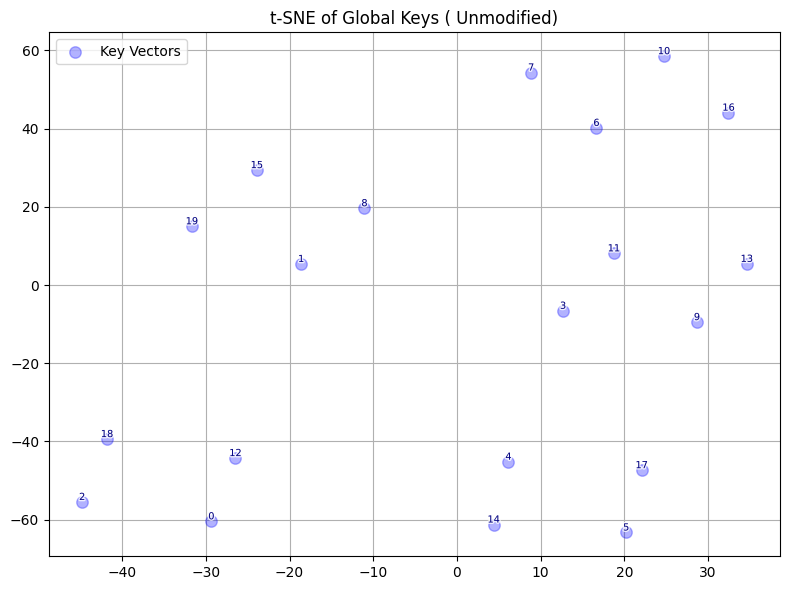

In [54]:
import matplotlib.patheffects as pe

# combine fixed keys + single query
combined = np.concatenate([fixed_key_norm], axis=0)

# t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=10)
tsne_result = tsne.fit_transform(combined)

key_count = len(fixed_key_norm)       # N_keys
query_index = key_count               # last row is the query

plt.figure(figsize=(8, 6))
plt.scatter(tsne_result[:key_count, 0], tsne_result[:key_count, 1],
            c='blue', alpha=0.3, s=68, label='Key Vectors', zorder=5)
# plt.scatter(tsne_result[query_index, 0], tsne_result[query_index, 1],
#             c='green', edgecolors='black', s=80, marker='X',
#             label=f'Query (id={sample_id})', zorder=20)

# --- annotate key indices ---
for i in range(key_count):
    x, y = tsne_result[i]
    plt.text(x, y, str(i), fontsize=7, ha='center', va='bottom', color='navy', zorder=30,
             path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.8)])

# # --- annotate query ---
# qx, qy = tsne_result[query_index]
# plt.text(qx, qy, "Q", fontsize=9, fontweight='bold', ha='center', va='bottom',
#          color='darkgreen', zorder=32,
#          path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.9)])

plt.title('t-SNE of Global Keys ( Unmodified)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Chosen (top-k) indices: [1, 8, 15, 19]
0.02
Injected Keys Indices: [1, 8, 15, 19]


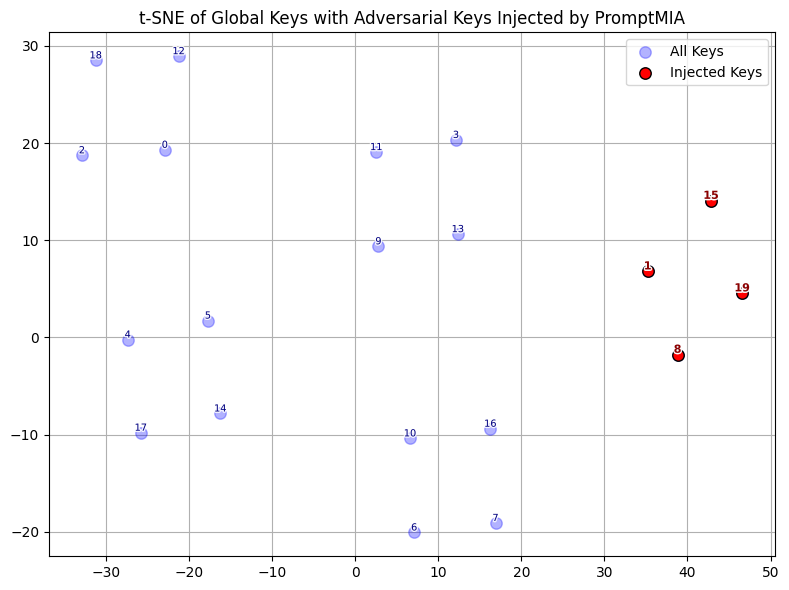

In [56]:
# --- your setup ---
args.beta = 0
k_top = 4
# similarity shape: (batch, key_count)
similarity = torch.matmul(x_embed_norm, fixed_key_norm_torch.t())  

# pick indices of top-k (for the first query in the batch)
topk_vals, topk_idxs = torch.topk(similarity[0], k=k_top, largest=True)
chosen_idx = topk_idxs.cpu().numpy().tolist()
print("Chosen (top-k) indices:", chosen_idx)

def generate_point_with_similarity(target_vec, similarity, benign_key):
    target_vec = target_vec.reshape(-1)
    benign_key = benign_key.reshape(-1)

    target_norm = target_vec / np.linalg.norm(target_vec)
    benign_norm = benign_key / np.linalg.norm(benign_key)

    rand_vec = np.random.rand(benign_key.shape[0])
    rand_vec = rand_vec / np.linalg.norm(rand_vec)

    beta = args.beta
    final_vec = (beta) * benign_norm + (1-beta) * rand_vec
    final_vec /= np.linalg.norm(final_vec)

    orthogonal_vec = final_vec - np.dot(final_vec, target_norm) * target_norm
    orthogonal_norm = orthogonal_vec / (np.linalg.norm(orthogonal_vec) + 1e-8)

    new_vec_norm = similarity * target_norm + np.sqrt(1 - similarity**2) * orthogonal_norm
    new_vec_norm /= np.linalg.norm(new_vec_norm)

    new_vec = new_vec_norm * np.linalg.norm(target_vec)
    return new_vec

# --- convert inputs to numpy ---
fixed_keys_np = fixed_keys.detach().cpu().numpy()
fixed_key_norm_temp = fixed_key_norm.copy()
query_vector_np = query_vector_train.detach().cpu().numpy().copy()

# --- find similarity thresholds excluding chosen_idx ---
#similarity = torch.matmul(x_embed_norm, fixed_key_norm_torch.t())
mask = np.ones(similarity.shape[1], dtype=bool)
mask[chosen_idx] = False
non_adv_similarity = similarity[:, mask] 
max_val, max_idx = torch.max(non_adv_similarity, dim=1)
# print(delta_min)
delta_min = 0.02
print(delta_min)
delta_max = args.delta_min + args.delta_max  # (same as you had)
similarity_start = torch.min(max_val + delta_min, torch.tensor(1, device=max_val.device)).cpu().item()
similarity_end   = torch.min(max_val + delta_max, torch.tensor(1, device=max_val.device)).cpu().item()
varied_target_similarities = np.random.uniform(similarity_start, similarity_end, args.n_tokens)

non_chosen = np.where(mask)[0]  # 'mask' already excludes chosen_idx above
anchor_idx = np.random.choice(non_chosen, size=len(chosen_idx), replace=False)
# --- generate adversarial vectors for chosen_idx ---
similar_points = []
for sim, idx in zip(varied_target_similarities, anchor_idx):
    benign_key = fixed_keys_np[idx:idx+1]
    new_point = generate_point_with_similarity(query_vector_np[0], sim, benign_key)
    similar_points.append(new_point)

similar_points_tensor = torch.tensor(similar_points, dtype=fixed_keys.dtype, device=fixed_keys.device)
similar_points_tensor_norm = algo.client_model[0].pool.l2_normalize(similar_points_tensor, dim=1)

fixed_key_norm_temp = fixed_key_norm.copy()
for i, idx in enumerate(chosen_idx):
    fixed_key_norm_temp[idx] = similar_points_tensor_norm[i].detach().cpu().numpy()

combined = np.concatenate([fixed_key_norm_temp], axis=0)

# --- t-SNE ---
key_count = len(fixed_key_norm)
tsne = TSNE(n_components=2, random_state=42, perplexity=10)
tsne_result = tsne.fit_transform(combined)

injected_idx = chosen_idx
print("Injected Keys Indices:", injected_idx)

# -----------------------------
# Base t-SNE plot
# -----------------------------
plt.figure(figsize=(8, 6))
plt.scatter(tsne_result[:key_count, 0], tsne_result[:key_count, 1],
            c='blue', alpha=0.3, s=68, label='All Keys', zorder=5)
plt.scatter(tsne_result[injected_idx, 0], tsne_result[injected_idx, 1],
            c='red', edgecolors='black', s=68, label='Injected Keys', zorder=10)
# annotate all keys
for i in range(key_count):
    x, y = tsne_result[i]
    plt.text(x, y, str(i), fontsize=7, ha='center', va='bottom',
             color='navy', zorder=30,
             path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.85)])
# emphasize injected keys
for i in injected_idx:
    x, y = tsne_result[i]
    plt.text(x, y, str(i), fontsize=8, fontweight='bold', ha='center', va='bottom',
             color='darkred', zorder=31,
             path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.9)])

plt.title('t-SNE of Global Keys with Adversarial Keys Injected by PromptMIA')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Chosen (top-k) indices: [1, 8, 15, 19]
0.02
Injected Keys Indices: [1, 8, 15, 19]


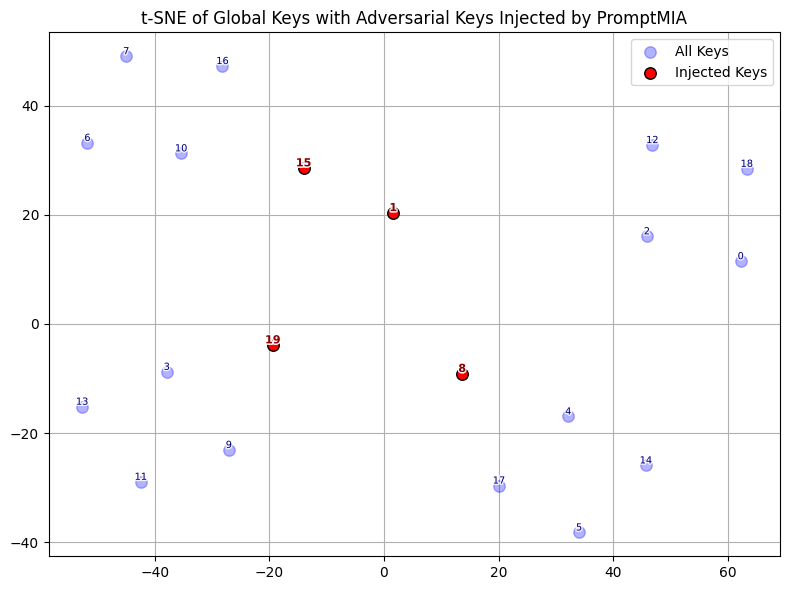

In [60]:
# --- your setup ---
args.beta = 0.6
k_top = 4
# similarity shape: (batch, key_count)
similarity = torch.matmul(x_embed_norm, fixed_key_norm_torch.t())  

# pick indices of top-k (for the first query in the batch)
topk_vals, topk_idxs = torch.topk(similarity[0], k=k_top, largest=True)
chosen_idx = topk_idxs.cpu().numpy().tolist()
print("Chosen (top-k) indices:", chosen_idx)

def generate_point_with_similarity(target_vec, similarity, benign_key):
    target_vec = target_vec.reshape(-1)
    benign_key = benign_key.reshape(-1)

    target_norm = target_vec / np.linalg.norm(target_vec)
    benign_norm = benign_key / np.linalg.norm(benign_key)

    rand_vec = np.random.rand(benign_key.shape[0])
    rand_vec = rand_vec / np.linalg.norm(rand_vec)

    beta = args.beta
    final_vec = (beta) * benign_norm + (1-beta) * rand_vec
    final_vec /= np.linalg.norm(final_vec)

    orthogonal_vec = final_vec - np.dot(final_vec, target_norm) * target_norm
    orthogonal_norm = orthogonal_vec / (np.linalg.norm(orthogonal_vec) + 1e-8)

    new_vec_norm = similarity * target_norm + np.sqrt(1 - similarity**2) * orthogonal_norm
    new_vec_norm /= np.linalg.norm(new_vec_norm)

    new_vec = new_vec_norm * np.linalg.norm(target_vec)
    return new_vec

# --- convert inputs to numpy ---
fixed_keys_np = fixed_keys.detach().cpu().numpy()
fixed_key_norm_temp = fixed_key_norm.copy()
query_vector_np = query_vector_train.detach().cpu().numpy().copy()

# --- find similarity thresholds excluding chosen_idx ---
#similarity = torch.matmul(x_embed_norm, fixed_key_norm_torch.t())
mask = np.ones(similarity.shape[1], dtype=bool)
mask[chosen_idx] = False
non_adv_similarity = similarity[:, mask] 
max_val, max_idx = torch.max(non_adv_similarity, dim=1)
# print(delta_min)
delta_min = 0.02
print(delta_min)
delta_max = args.delta_min + args.delta_max  # (same as you had)
similarity_start = torch.min(max_val + delta_min, torch.tensor(1, device=max_val.device)).cpu().item()
similarity_end   = torch.min(max_val + delta_max, torch.tensor(1, device=max_val.device)).cpu().item()
varied_target_similarities = np.random.uniform(similarity_start, similarity_end, args.n_tokens)

non_chosen = np.where(mask)[0]  # 'mask' already excludes chosen_idx above
anchor_idx = np.random.choice(non_chosen, size=len(chosen_idx), replace=False)
# --- generate adversarial vectors for chosen_idx ---
similar_points = []
for sim, idx in zip(varied_target_similarities, anchor_idx):
    benign_key = fixed_keys_np[idx:idx+1]
    new_point = generate_point_with_similarity(query_vector_np[0], sim, benign_key)
    similar_points.append(new_point)

similar_points_tensor = torch.tensor(similar_points, dtype=fixed_keys.dtype, device=fixed_keys.device)
similar_points_tensor_norm = algo.client_model[0].pool.l2_normalize(similar_points_tensor, dim=1)

fixed_key_norm_temp = fixed_key_norm.copy()
for i, idx in enumerate(chosen_idx):
    fixed_key_norm_temp[idx] = similar_points_tensor_norm[i].detach().cpu().numpy()

combined = np.concatenate([fixed_key_norm_temp], axis=0)

# --- t-SNE ---
key_count = len(fixed_key_norm)
tsne = TSNE(n_components=2, random_state=42, perplexity=10)
tsne_result = tsne.fit_transform(combined)

injected_idx = chosen_idx
print("Injected Keys Indices:", injected_idx)

# -----------------------------
# Base t-SNE plot
# -----------------------------
plt.figure(figsize=(8, 6))
plt.scatter(tsne_result[:key_count, 0], tsne_result[:key_count, 1],
            c='blue', alpha=0.3, s=68, label='All Keys', zorder=5)
plt.scatter(tsne_result[injected_idx, 0], tsne_result[injected_idx, 1],
            c='red', edgecolors='black', s=68, label='Injected Keys', zorder=10)
# annotate all keys
for i in range(key_count):
    x, y = tsne_result[i]
    plt.text(x, y, str(i), fontsize=7, ha='center', va='bottom',
             color='navy', zorder=30,
             path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.85)])
# emphasize injected keys
for i in injected_idx:
    x, y = tsne_result[i]
    plt.text(x, y, str(i), fontsize=8, fontweight='bold', ha='center', va='bottom',
             color='darkred', zorder=31,
             path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.9)])

plt.title('t-SNE of Global Keys with Adversarial Keys Injected by PromptMIA')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

0.02


Injected Keys Indices: [16, 17, 18, 19]


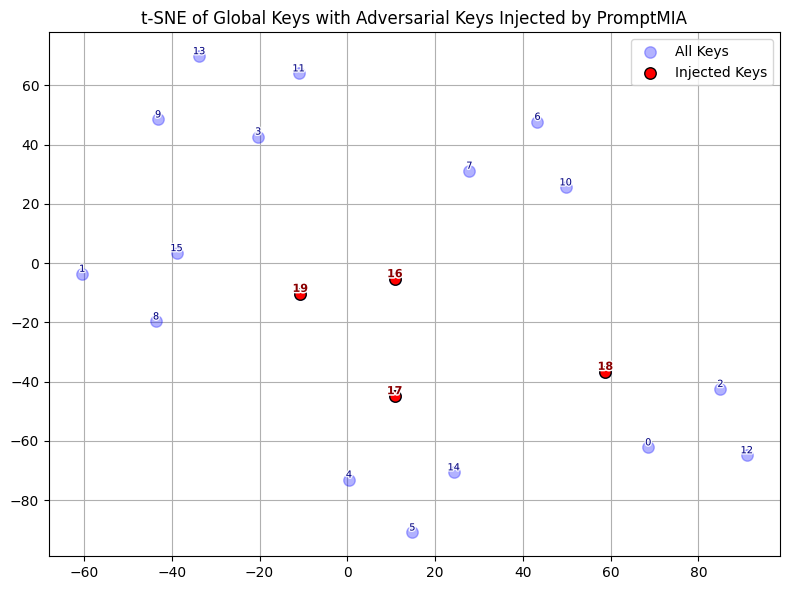

In [17]:
# --- your setup ---
args.beta = 1
chosen_idx = [16, 17, 18, 19]

def generate_point_with_similarity(target_vec, similarity, benign_key):
    target_vec = target_vec.reshape(-1)
    benign_key = benign_key.reshape(-1)

    target_norm = target_vec / np.linalg.norm(target_vec)
    benign_norm = benign_key / np.linalg.norm(benign_key)

    rand_vec = np.random.rand(benign_key.shape[0])
    rand_vec = rand_vec / np.linalg.norm(rand_vec)

    beta = args.beta
    final_vec = (beta) * benign_norm + (1-beta) * rand_vec
    final_vec /= np.linalg.norm(final_vec)

    orthogonal_vec = final_vec - np.dot(final_vec, target_norm) * target_norm
    orthogonal_norm = orthogonal_vec / (np.linalg.norm(orthogonal_vec) + 1e-8)

    new_vec_norm = similarity * target_norm + np.sqrt(1 - similarity**2) * orthogonal_norm
    new_vec_norm /= np.linalg.norm(new_vec_norm)

    new_vec = new_vec_norm * np.linalg.norm(target_vec)
    return new_vec

# --- convert inputs to numpy ---
fixed_keys_np = fixed_keys.detach().cpu().numpy()
fixed_key_norm_temp = fixed_key_norm.copy()
query_vector_np = query_vector_train.detach().cpu().numpy().copy()

# --- find similarity thresholds excluding chosen_idx ---
similarity = torch.matmul(x_embed_norm, fixed_key_norm_torch.t())
mask = np.ones(similarity.shape[1], dtype=bool)
mask[chosen_idx] = False
non_adv_similarity = similarity[:, mask] 
max_val, max_idx = torch.max(non_adv_similarity, dim=1)
# print(delta_min)
delta_min = 0.02
print(delta_min)
delta_max = args.delta_min + args.delta_max  # (same as you had)
similarity_start = torch.min(max_val + delta_min, torch.tensor(1, device=max_val.device)).cpu().item()
similarity_end   = torch.min(max_val + delta_max, torch.tensor(1, device=max_val.device)).cpu().item()
varied_target_similarities = np.random.uniform(similarity_start, similarity_end, args.n_tokens)

# --- generate adversarial vectors for chosen_idx ---
similar_points = []
for sim, idx in zip(varied_target_similarities, chosen_idx):
    benign_key = fixed_keys_np[idx:idx+1]
    new_point = generate_point_with_similarity(query_vector_np[0], sim, benign_key)
    similar_points.append(new_point)

similar_points_tensor = torch.tensor(similar_points, dtype=fixed_keys.dtype, device=fixed_keys.device)
similar_points_tensor_norm = algo.client_model[0].pool.l2_normalize(similar_points_tensor, dim=1)

fixed_key_norm_temp = fixed_key_norm.copy()
for i, idx in enumerate(chosen_idx):
    fixed_key_norm_temp[idx] = similar_points_tensor_norm[i].detach().cpu().numpy()

combined = np.concatenate([fixed_key_norm_temp], axis=0)

# --- t-SNE ---
key_count = len(fixed_key_norm)
tsne = TSNE(n_components=2, random_state=42, perplexity=10)
tsne_result = tsne.fit_transform(combined)

injected_idx = chosen_idx
print("Injected Keys Indices:", injected_idx)

# -----------------------------
# Base t-SNE plot
# -----------------------------
plt.figure(figsize=(8, 6))
plt.scatter(tsne_result[:key_count, 0], tsne_result[:key_count, 1],
            c='blue', alpha=0.3, s=68, label='All Keys', zorder=5)
plt.scatter(tsne_result[injected_idx, 0], tsne_result[injected_idx, 1],
            c='red', edgecolors='black', s=68, label='Injected Keys', zorder=10)
# annotate all keys
for i in range(key_count):
    x, y = tsne_result[i]
    plt.text(x, y, str(i), fontsize=7, ha='center', va='bottom',
             color='navy', zorder=30,
             path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.85)])
# emphasize injected keys
for i in injected_idx:
    x, y = tsne_result[i]
    plt.text(x, y, str(i), fontsize=8, fontweight='bold', ha='center', va='bottom',
             color='darkred', zorder=31,
             path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.9)])

plt.title('t-SNE of Global Keys with Adversarial Keys Injected by PromptMIA')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()